# Day 48: charts and exploratory data analysis

UrbanKart Data Analyst Training. Put UrbanKart_orders.csv and UrbanKart_products.csv next to this notebook (Colab: folder icon → Upload). Run the cells in order: later tasks reuse variables (monthly, cat, fig) from earlier ones.

**Example.** Load and prepare the data (orders + products, profit, month), then draw a line chart of monthly sales.

(3288, 19)


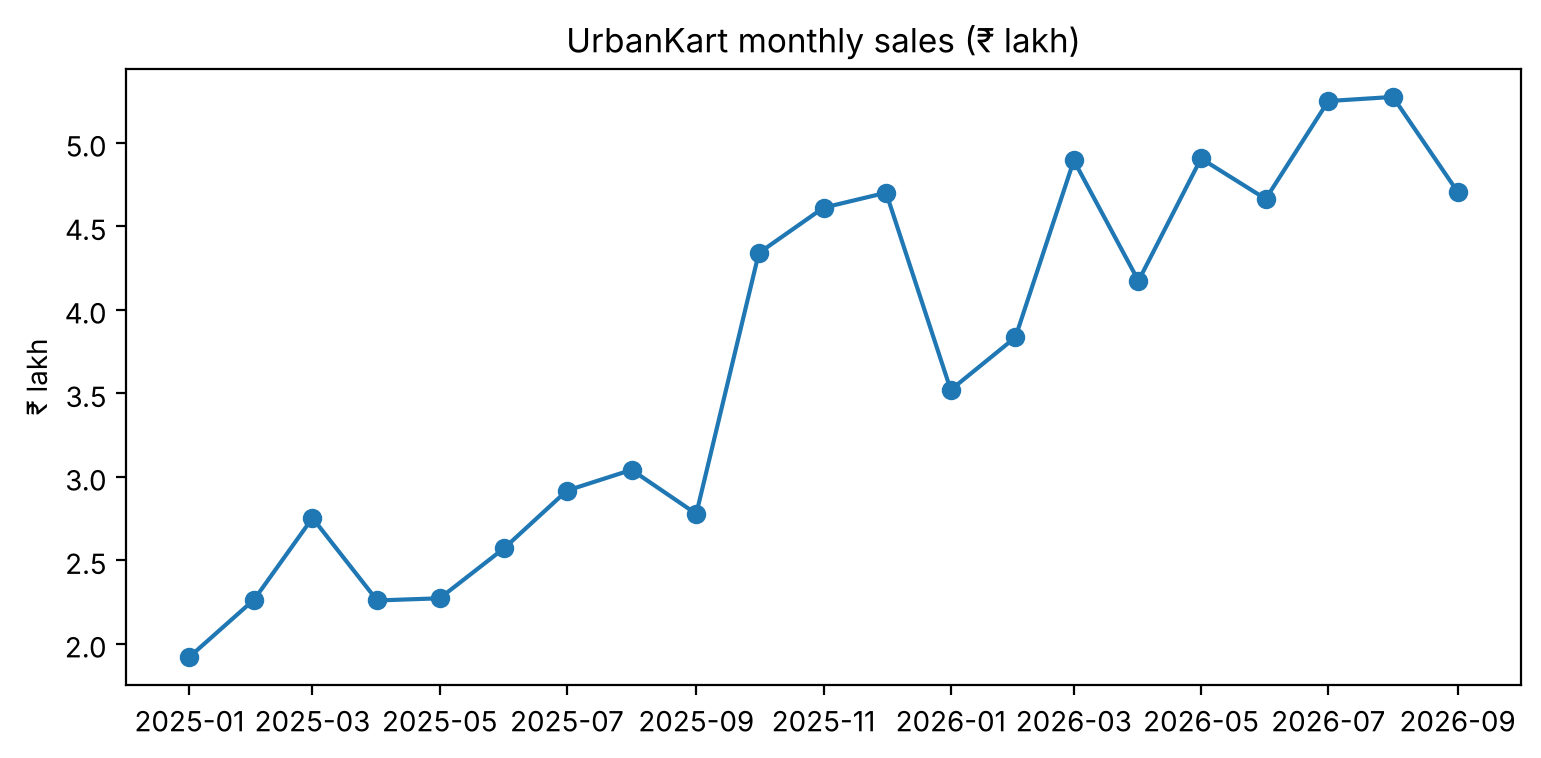

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (9, 4)
orders = pd.read_csv('UrbanKart_orders.csv', parse_dates=['order_date', 'delivery_date'])
products = pd.read_csv('UrbanKart_products.csv')
df = orders.merge(products, on='product_id', how='left')
df['profit'] = df['sales'] - df['quantity'] * df['cost_price']
df['month'] = df['order_date'].dt.to_period('M').dt.to_timestamp()
print(df.shape)

monthly = df.groupby('month')['sales'].sum()
plt.plot(monthly.index, monthly.values / 1e5, marker='o')
plt.title('UrbanKart monthly sales (₹ lakh)')
plt.ylabel('₹ lakh')
plt.show()

**T1.** Horizontal bar chart of total sales by category, largest at the top.

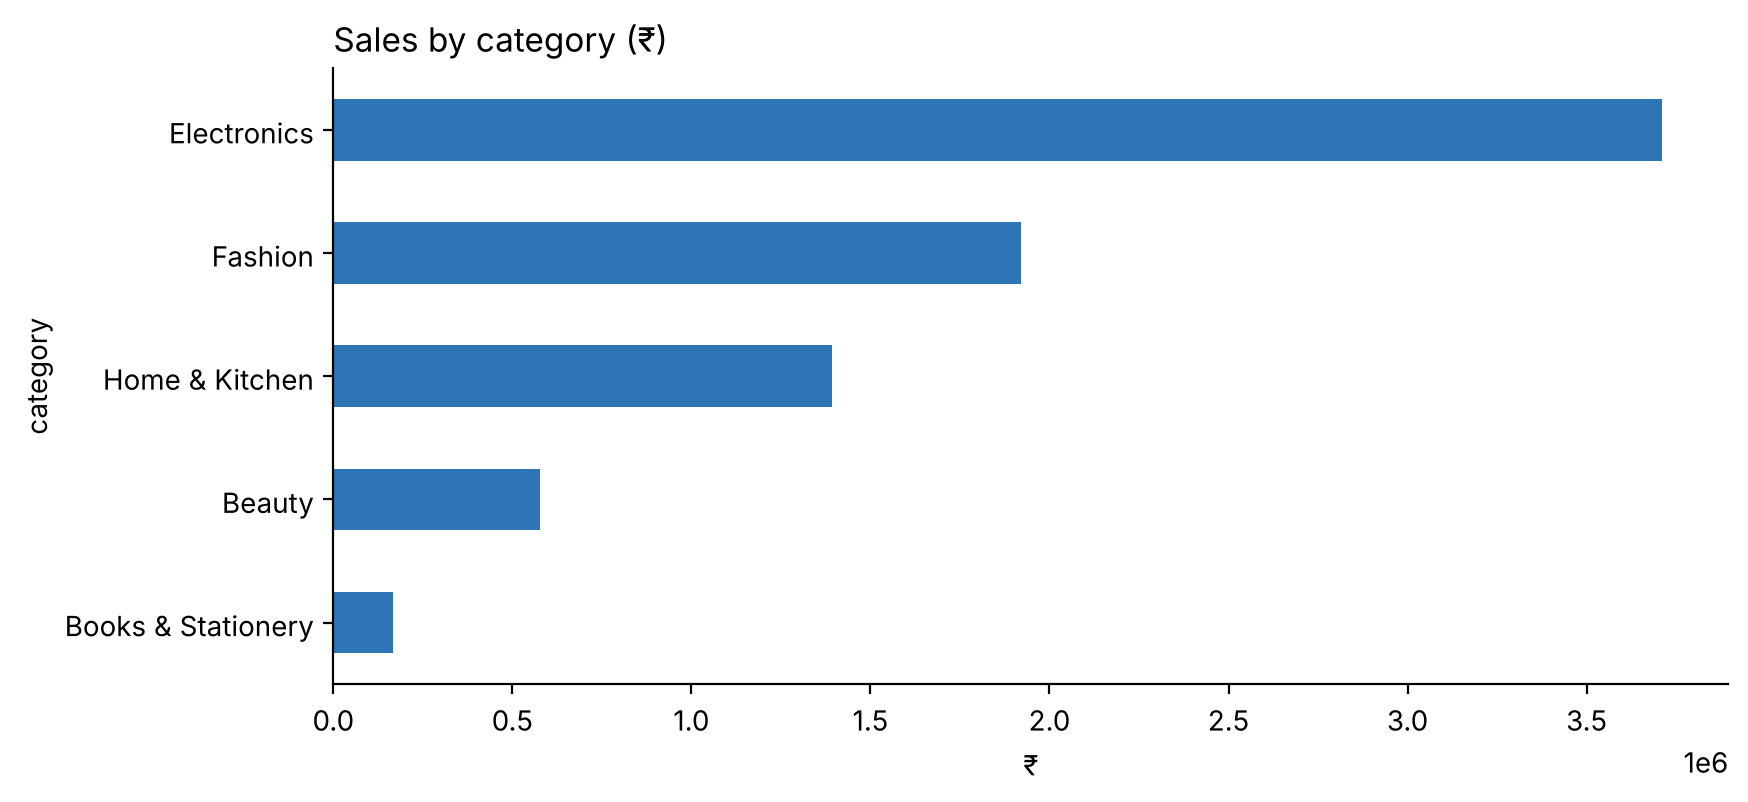

category
Electronics           3710329
Fashion               1919658
Home & Kitchen        1393850
Beauty                 577476
Books & Stationery     166459
Name: sales, dtype: int64

In [2]:
cat = df.groupby('category')['sales'].sum().sort_values()
ax = cat.plot(kind='barh', color='#2E75B6')
ax.set_title('Sales by category (₹)', loc='left')
ax.set_xlabel('₹')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
cat.sort_values(ascending=False)

**T2.** Histogram of order values (sales) with 40 bins. Is the distribution skewed?

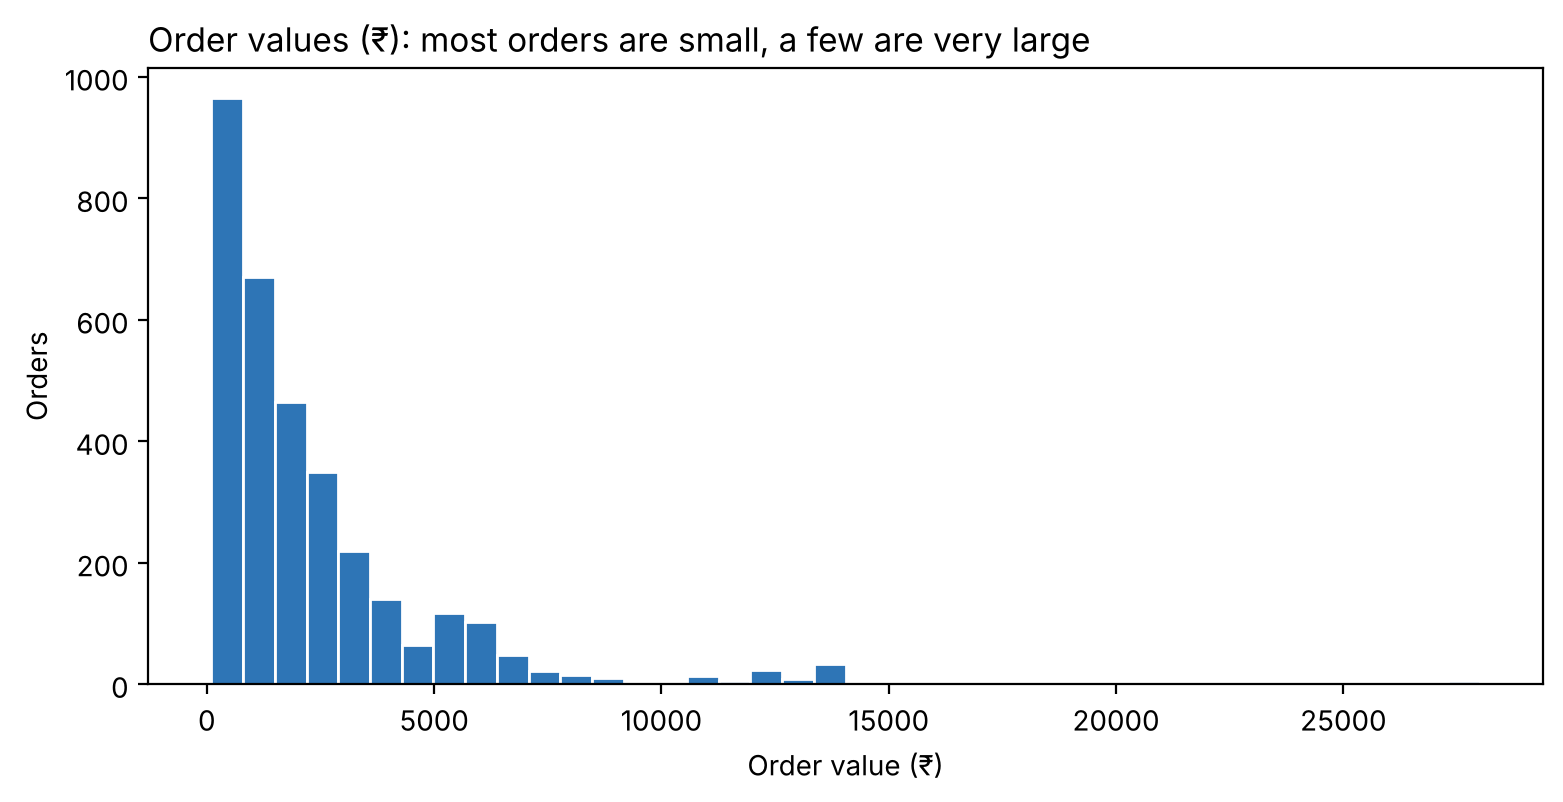

mean 2362 · median 1499.0 → right-skewed (mean > median)


In [3]:
plt.hist(df['sales'], bins=40, color='#2E75B6', edgecolor='white')
plt.title('Order values (₹): most orders are small, a few are very large', loc='left')
plt.xlabel('Order value (₹)'); plt.ylabel('Orders')
plt.show()
print('mean', round(df['sales'].mean()), '· median', df['sales'].median(), '→ right-skewed (mean > median)')

**T3.** Box plot of order values by category (seaborn). Which category has the widest spread?

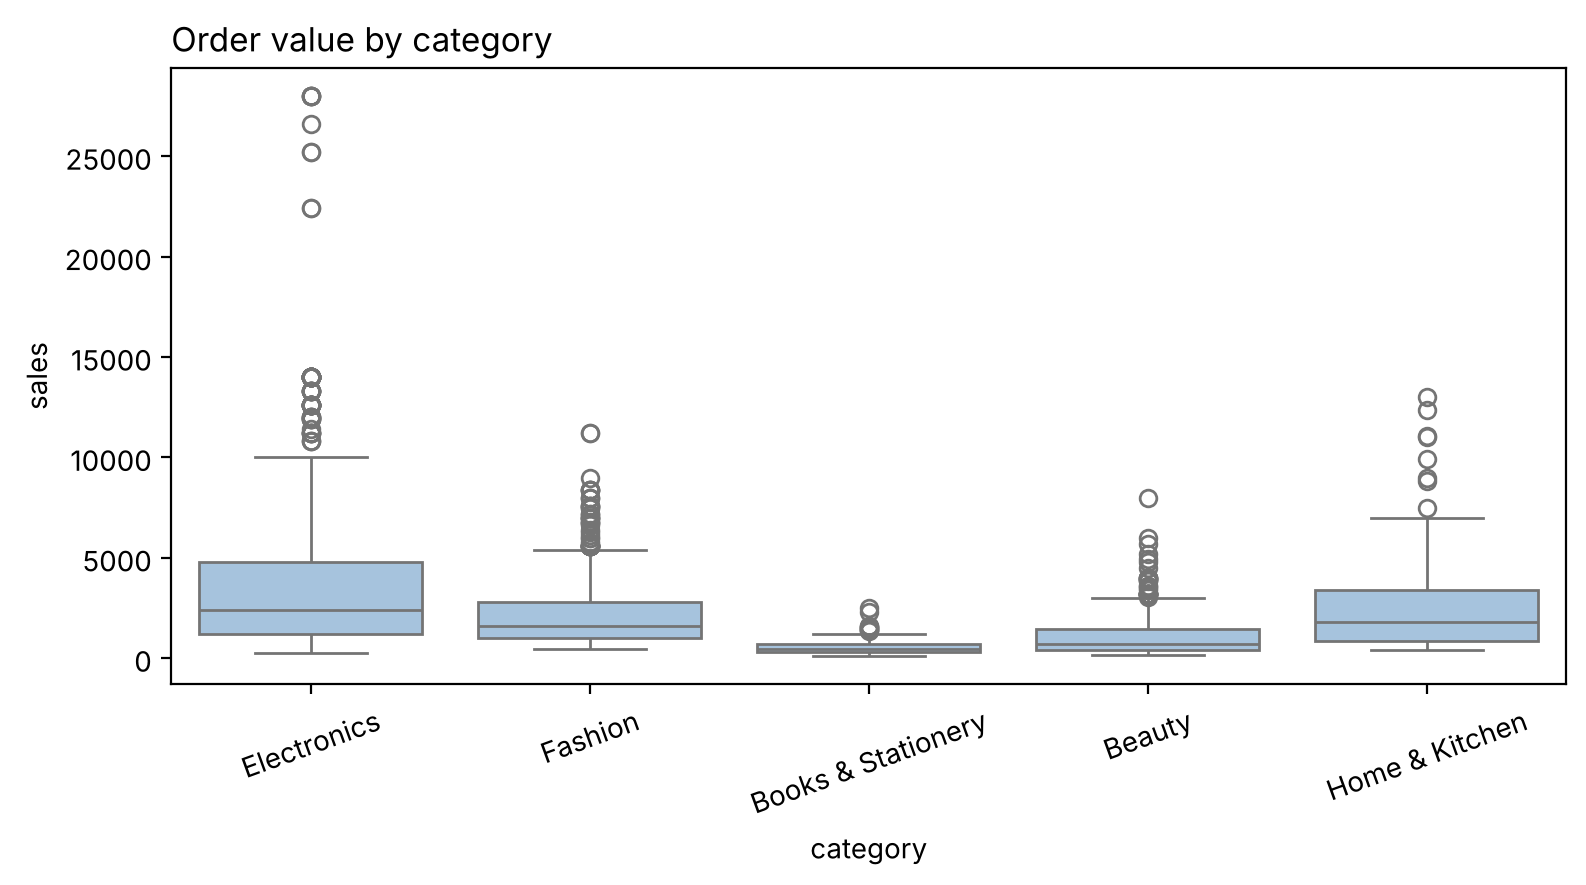

,0.25,0.75,IQR
category,,,
Electronics,1199.0,4798.0,3599.0
Home & Kitchen,854.0,3370.5,2516.5
Fashion,999.0,2799.0,1800.0
Beauty,399.0,1439.0,1040.0
Books & Stationery,299.0,718.0,419.0


In [4]:
sns.boxplot(data=df, x='category', y='sales', color='#9DC3E6')
plt.title('Order value by category', loc='left')
plt.xticks(rotation=20)
plt.show()
df.groupby('category')['sales'].quantile([0.25, 0.75]).unstack().assign(IQR=lambda t: t[0.75] - t[0.25]).sort_values('IQR', ascending=False)

**T4.** Bar chart of the number of orders by payment mode, with the percentage on each bar.

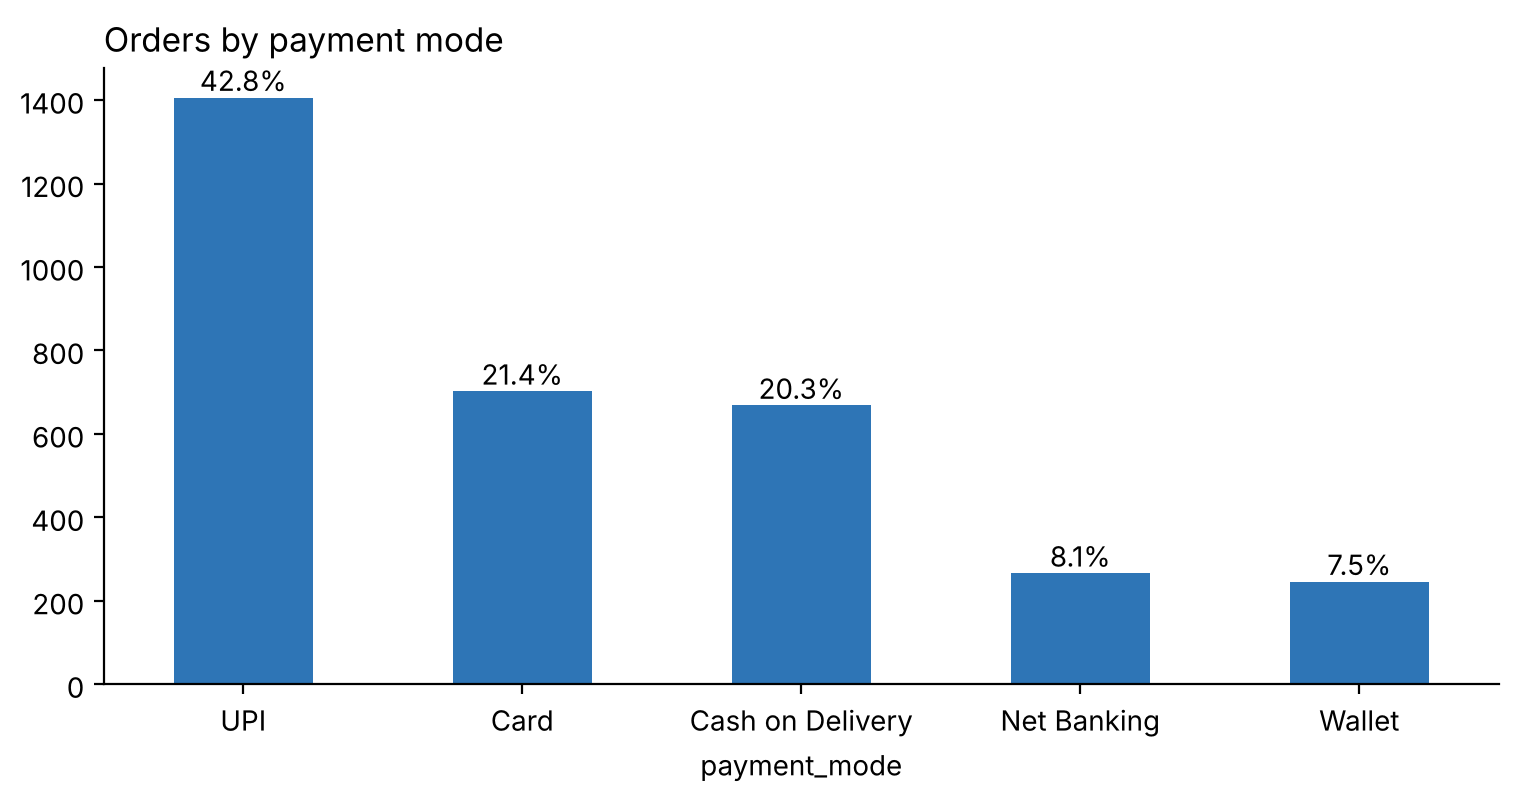

In [5]:
pm = df['payment_mode'].value_counts()
ax = pm.plot(kind='bar', color='#2E75B6')
for i, v in enumerate(pm):
    ax.text(i, v, f'{v / pm.sum():.1%}', ha='center', va='bottom')
ax.set_title('Orders by payment mode', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=0)
plt.show()

**T5.** Compare monthly sales for 2025 and 2026 (Jan–Sep) in one line chart with a legend.

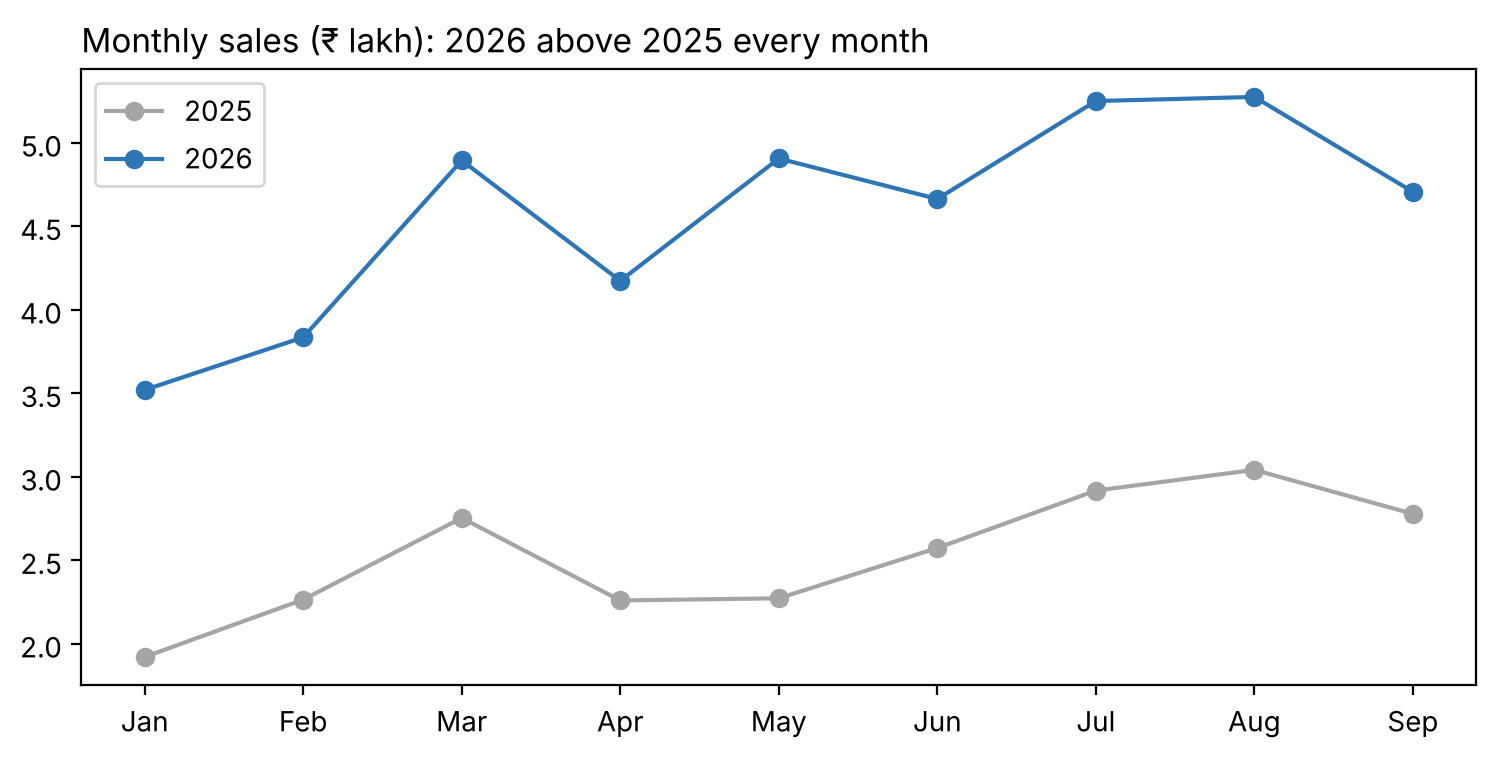

year,2025,2026
mon,,
1,1.92,3.52
2,2.27,3.84
3,2.75,4.90
4,2.26,4.17
5,2.27,4.91
6,2.57,4.66
7,2.92,5.25
8,3.04,5.28
9,2.78,4.71


In [6]:
df['year'] = df['order_date'].dt.year
df['mon'] = df['order_date'].dt.month
yy = df[df['mon'] <= 9].pivot_table(index='mon', columns='year', values='sales', aggfunc='sum')
for y, c in [(2025, '#A5A5A5'), (2026, '#2E75B6')]:
    plt.plot(yy.index, yy[y] / 1e5, marker='o', color=c, label=str(y))
plt.xticks(range(1, 10), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'])
plt.title('Monthly sales (₹ lakh): 2026 above 2025 every month', loc='left')
plt.legend(); plt.show()
(yy / 1e5).round(2)

**T6.** Scatter plot per product: selling price (x) vs units sold (y), coloured by category.

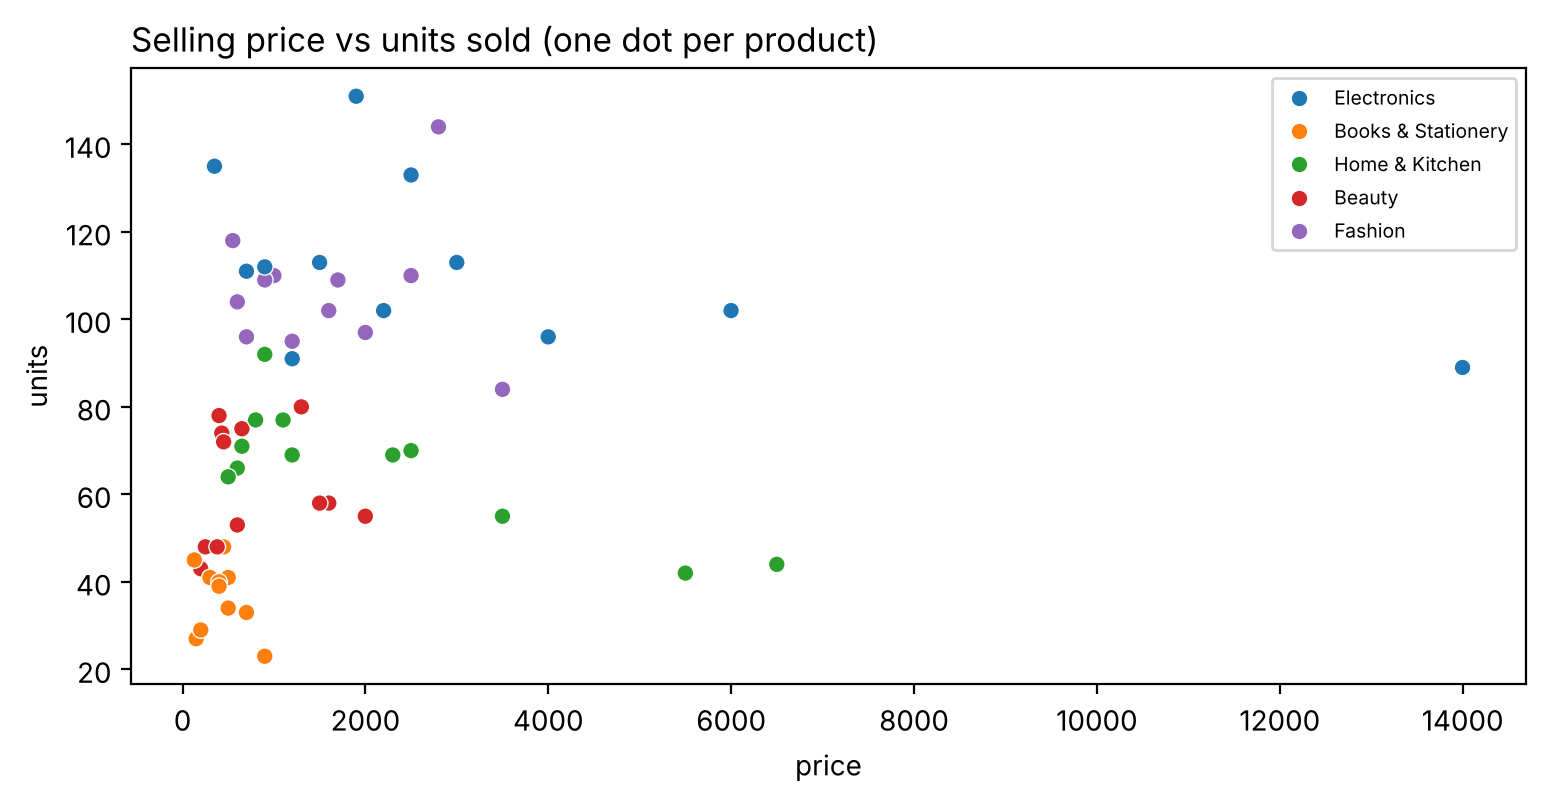

np.float64(0.17)

In [7]:
pp = df.groupby(['product_name', 'category']).agg(units=('quantity', 'sum'), price=('selling_price', 'first')).reset_index()
sns.scatterplot(data=pp, x='price', y='units', hue='category')
plt.title('Selling price vs units sold (one dot per product)', loc='left')
plt.legend(fontsize=7)
plt.show()
round(pp['price'].corr(pp['units']), 2)

**T7.** Heatmap of sales (₹ lakh) by city (top 6) and category.

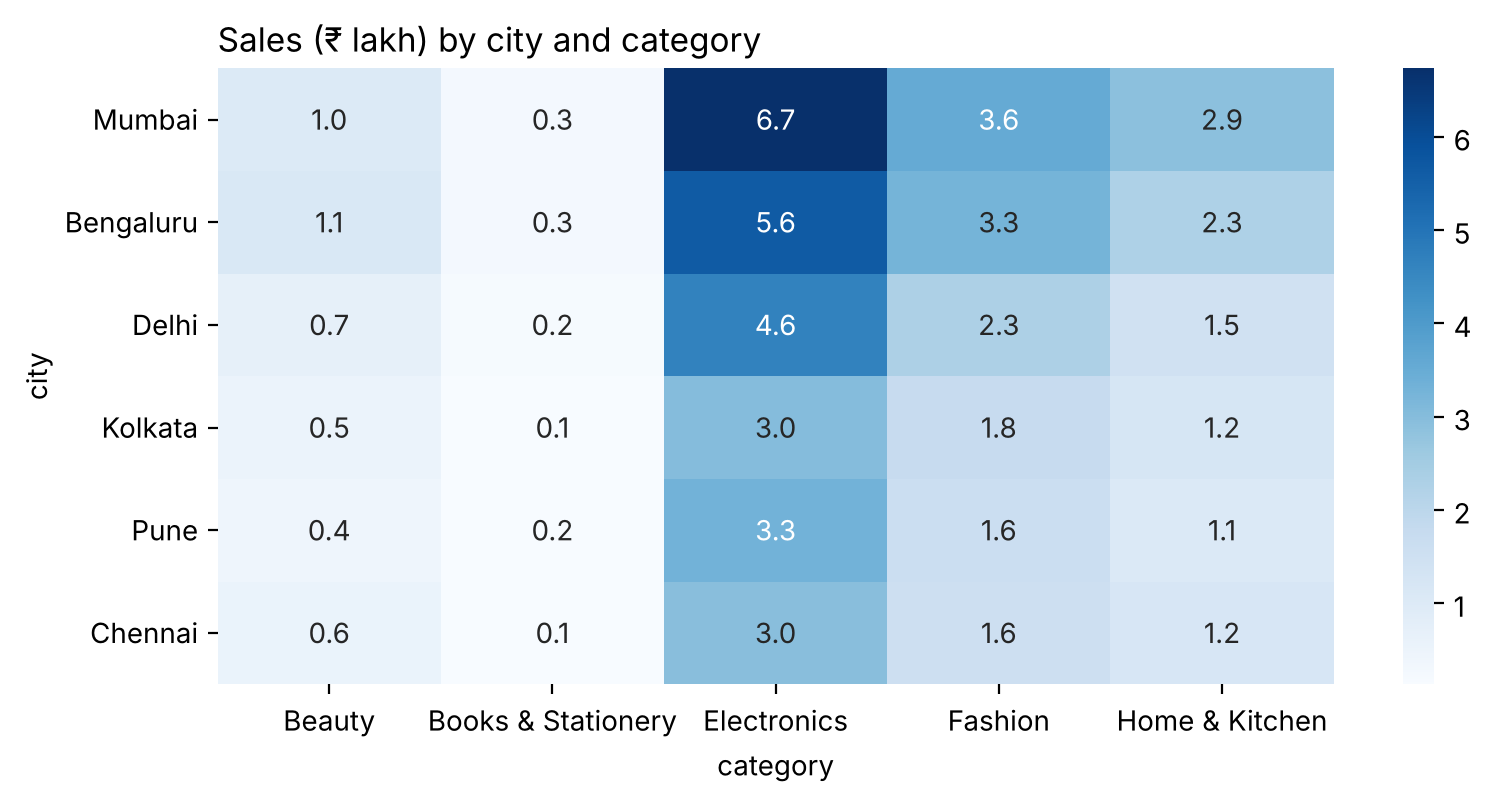

In [8]:
top6 = df.groupby('city')['sales'].sum().nlargest(6).index
hm = df[df['city'].isin(top6)].pivot_table(index='city', columns='category', values='sales', aggfunc='sum') / 1e5
sns.heatmap(hm.loc[top6], annot=True, fmt='.1f', cmap='Blues')
plt.title('Sales (₹ lakh) by city and category', loc='left')
plt.show()

**T8.** 100% stacked bar: order status share for each payment mode.

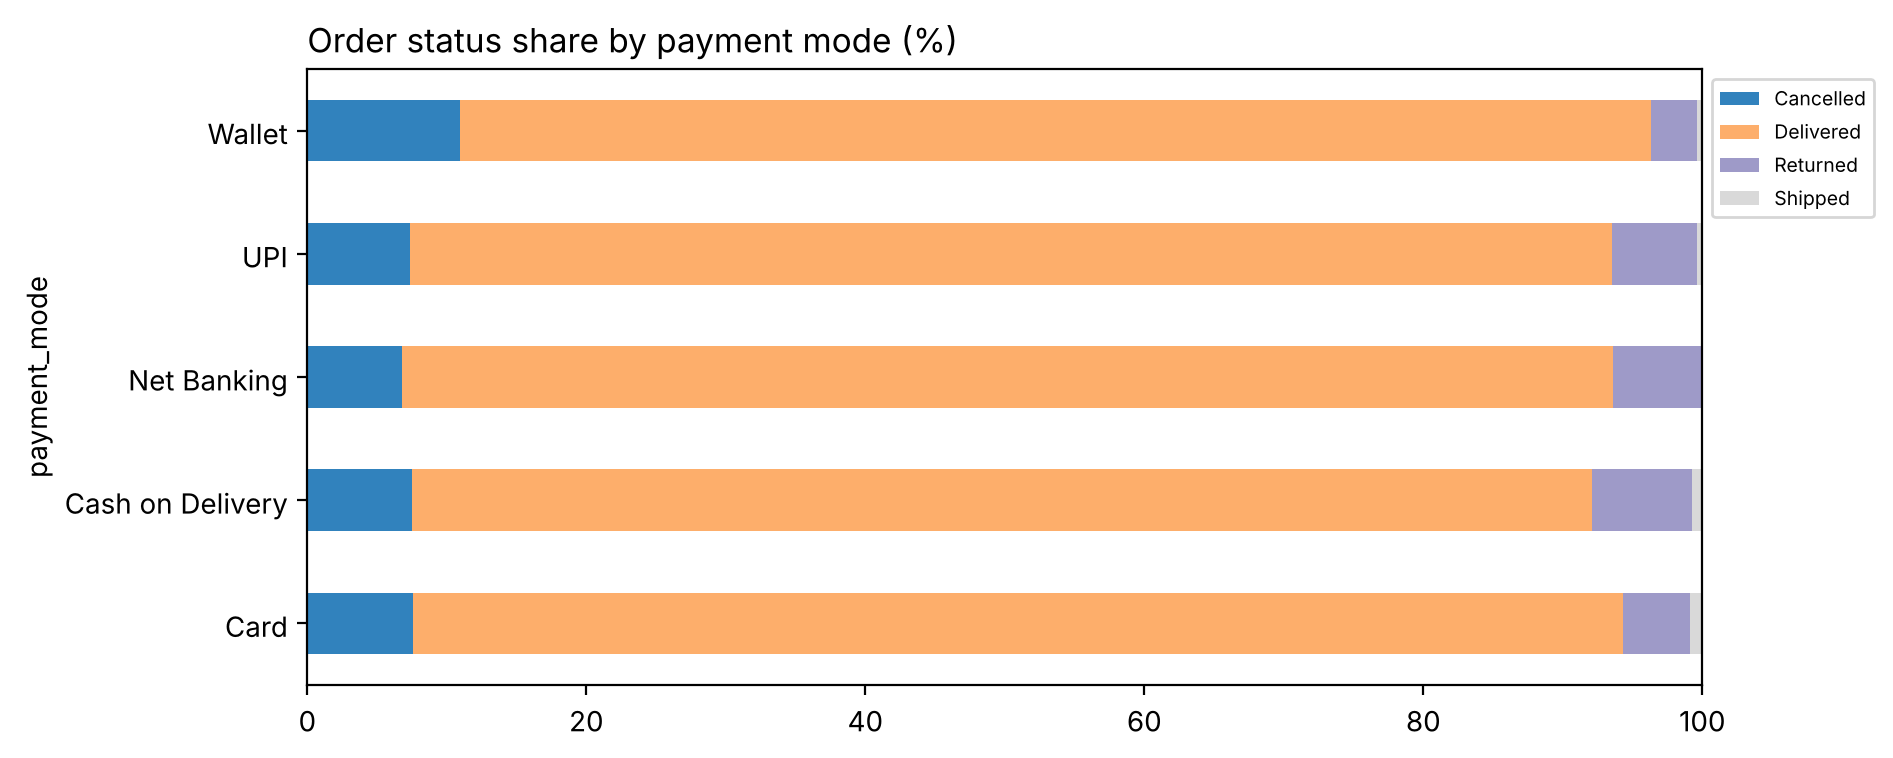

order_status,Cancelled,Delivered,Returned,Shipped
payment_mode,,,,
Card,7.5,86.8,4.8,0.9
Cash on Delivery,7.5,84.6,7.2,0.7
Net Banking,6.8,86.8,6.4,0.0
UPI,7.4,86.1,6.1,0.4
Wallet,11.0,85.4,3.3,0.4


In [9]:
st = pd.crosstab(df['payment_mode'], df['order_status'], normalize='index') * 100
st.plot(kind='barh', stacked=True, colormap='tab20c')
plt.title('Order status share by payment mode (%)', loc='left')
plt.legend(bbox_to_anchor=(1, 1), fontsize=7)
plt.show()
st.round(1)

**T9.** A 2×2 mini dashboard with subplots: monthly sales, category sales, order value histogram, margin % by category.

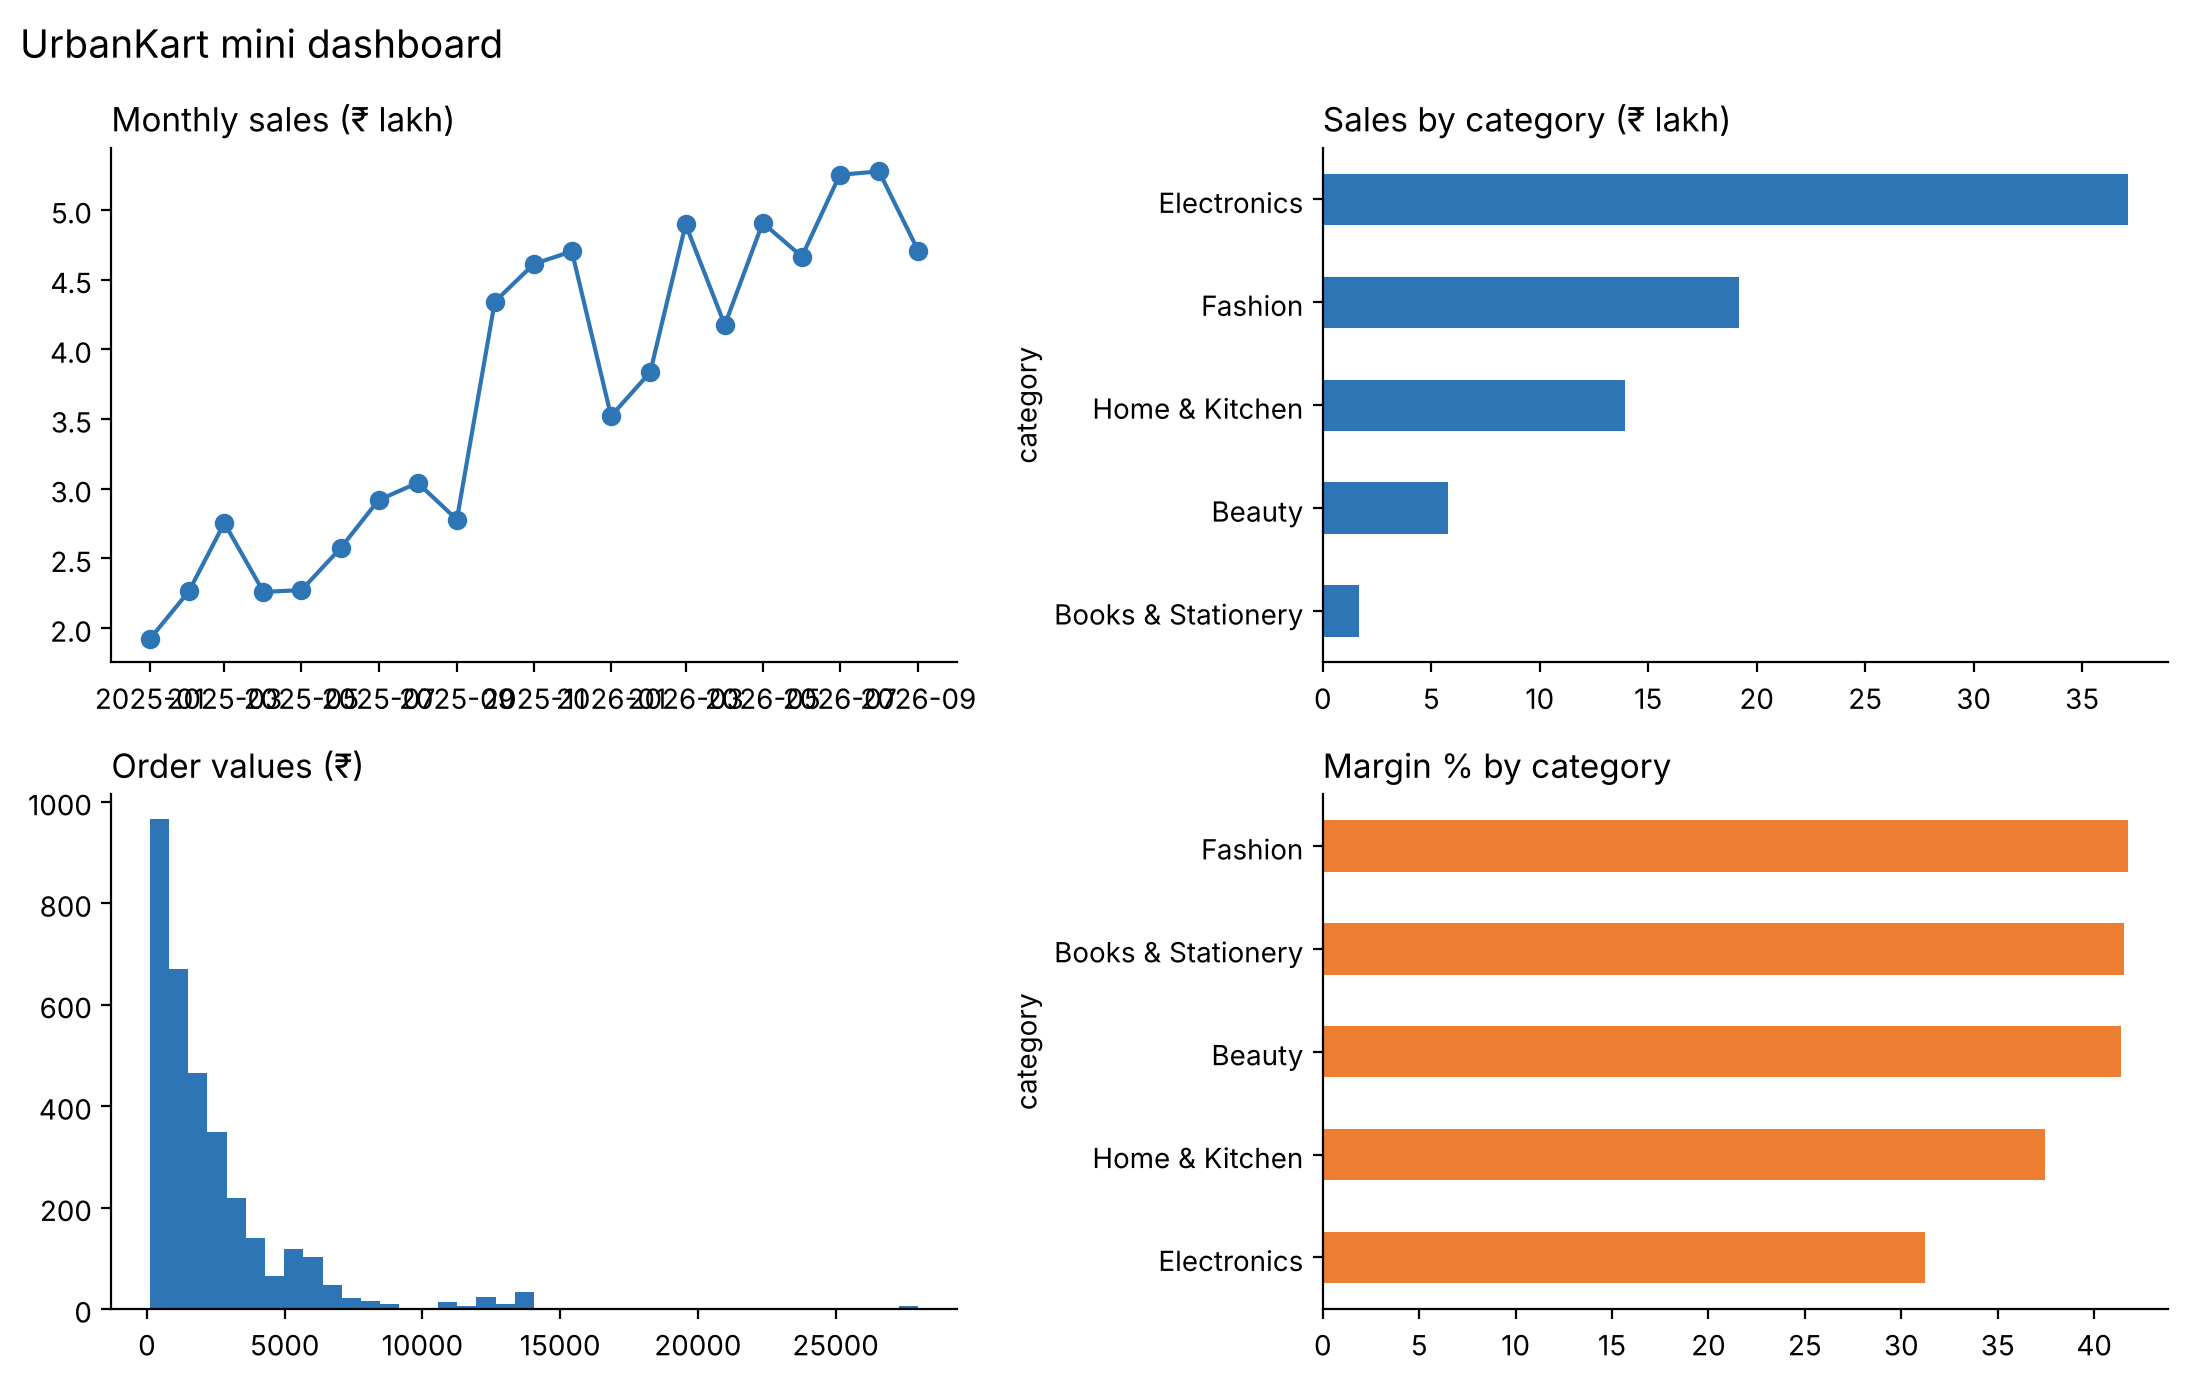

In [10]:
cat_m = df.groupby('category')[['sales', 'profit']].sum()
cat_m['margin'] = cat_m['profit'] / cat_m['sales'] * 100
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
axs[0, 0].plot(monthly.index, monthly / 1e5, marker='o', color='#2E75B6'); axs[0, 0].set_title('Monthly sales (₹ lakh)', loc='left')
(cat_m['sales'].sort_values() / 1e5).plot(kind='barh', ax=axs[0, 1], color='#2E75B6'); axs[0, 1].set_title('Sales by category (₹ lakh)', loc='left')
axs[1, 0].hist(df['sales'], bins=40, color='#2E75B6'); axs[1, 0].set_title('Order values (₹)', loc='left')
cat_m['margin'].sort_values().plot(kind='barh', ax=axs[1, 1], color='#ED7D31'); axs[1, 1].set_title('Margin % by category', loc='left')
for a in axs.flat:
    a.spines[['top', 'right']].set_visible(False)
fig.suptitle('UrbanKart mini dashboard', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.show()

**T10.** Story chart: monthly sales line with the best month highlighted and annotated, no clutter.

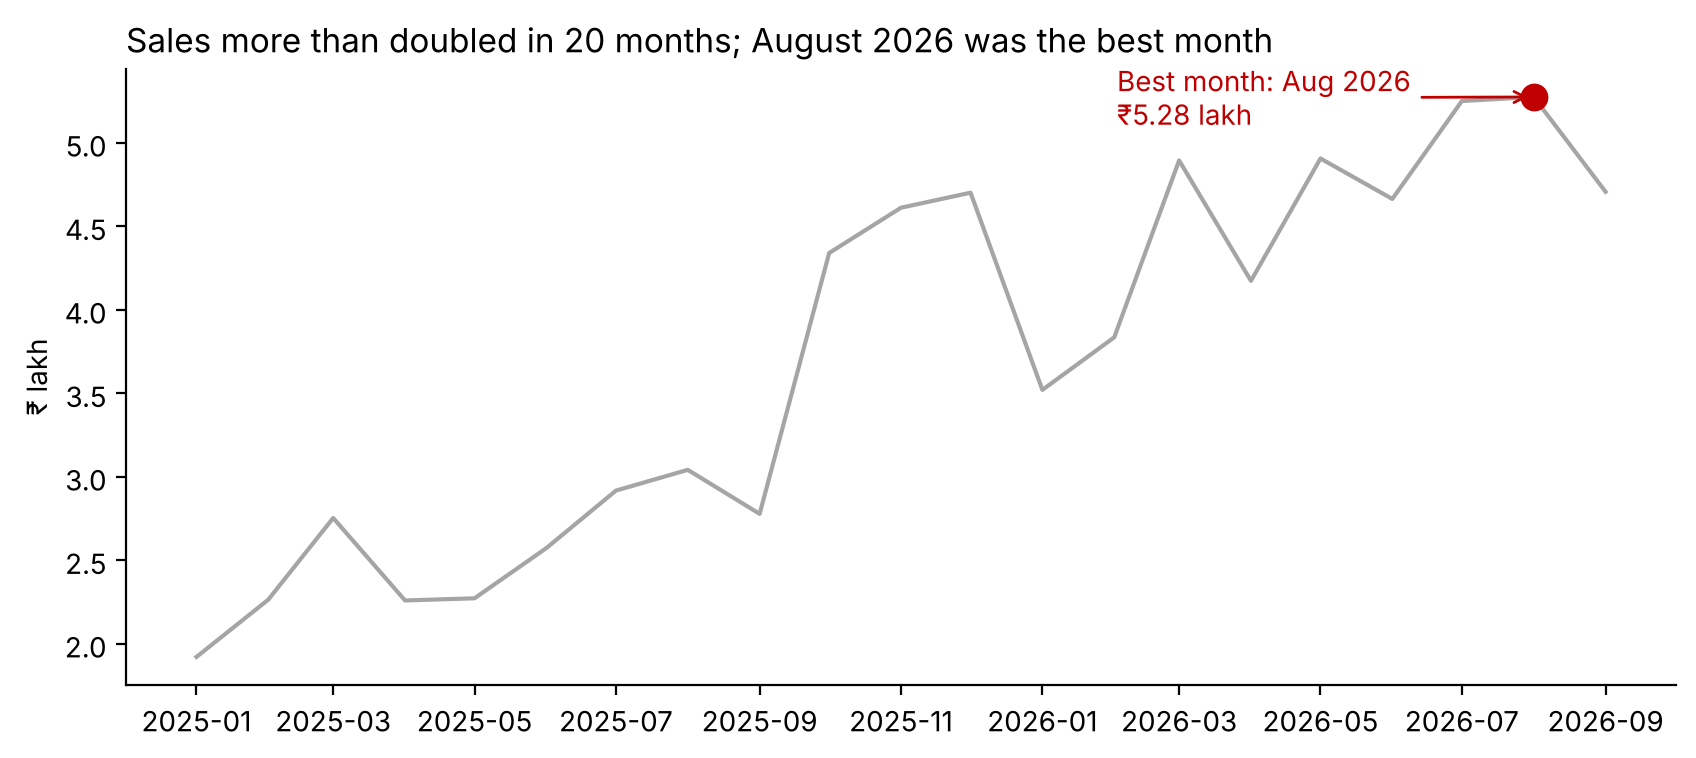

In [11]:
best = monthly.idxmax()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly / 1e5, color='#A5A5A5')
ax.plot(best, monthly.max() / 1e5, 'o', color='#C00000', ms=9)
ax.annotate(f"Best month: {best:%b %Y}\n₹{monthly.max() / 1e5:.2f} lakh", (best, monthly.max() / 1e5),
            xytext=(-150, -10), textcoords='offset points', color='#C00000', arrowprops={'arrowstyle': '->', 'color': '#C00000'})
ax.set_title('Sales more than doubled in 20 months; August 2026 was the best month', loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.set_ylabel('₹ lakh')
plt.show()

**T11.** Save the T9 dashboard figure as a PNG file (dpi=150).

In [12]:
fig.savefig('urbankart_dashboard.png', dpi=150, bbox_inches='tight')
import os
print('saved urbankart_dashboard.png', round(os.path.getsize('urbankart_dashboard.png') / 1024), 'KB')

saved urbankart_dashboard.png 65 KB


**T12.** EDA: correlation matrix of quantity, unit_price, discount_pct, sales and profit, as a heatmap.

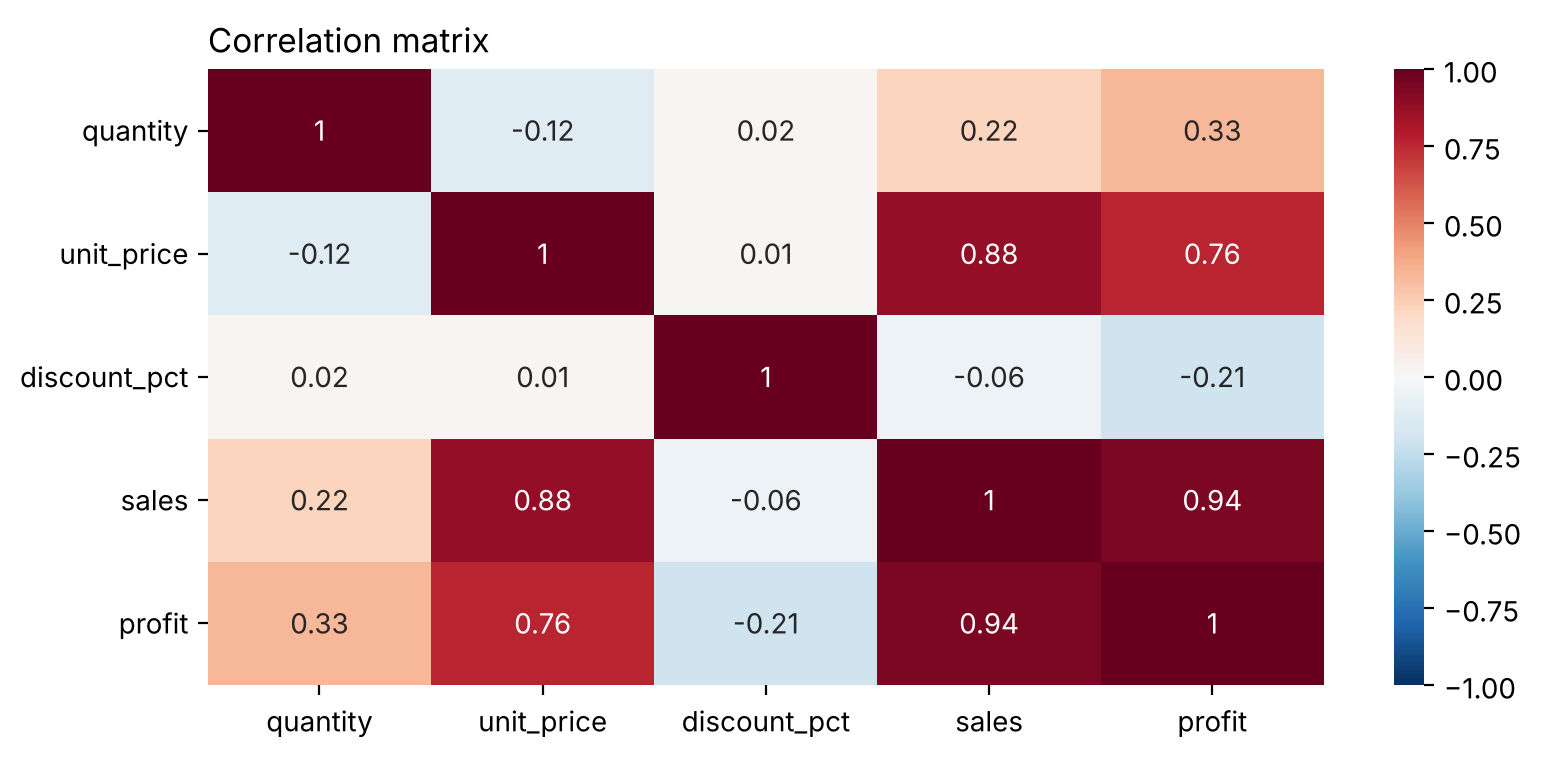

,quantity,unit_price,discount_pct,sales,profit
quantity,1.00,-0.12,0.02,0.22,0.33
unit_price,-0.12,1.00,0.01,0.88,0.76
discount_pct,0.02,0.01,1.00,-0.06,-0.21
sales,0.22,0.88,-0.06,1.00,0.94
profit,0.33,0.76,-0.21,0.94,1.00


In [13]:
corr = df[['quantity', 'unit_price', 'discount_pct', 'sales', 'profit']].corr().round(2)
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlation matrix', loc='left')
plt.show()
corr